Overfitting and Evaluation

In this notebook, I am checking how to tell whether a model is learning patterns that generalize or mostly memorizing the training data. I will use the CIFAR-10 results from my Module 1 CNN as the starting point, then practice reading training and validation metrics.

1. Results from Module 1

These are the values from my completed CIFAR-10 run. The training accuracy increased a lot, while validation performance levelled off near the end.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Results copied from the Module 1 run
results = {
    "epoch": [5, 7, 8, 10],
    "train_accuracy": [77.34, 82.81, 85.26, 89.70],
    "val_accuracy": [73.54, 74.28, 74.94, 74.84],
    "val_loss": [0.7554, 0.7474, 0.7687, 0.8398]
}

df = pd.DataFrame(results)
df

,epoch,train_accuracy,val_accuracy,val_loss
0,5,77.34,73.54,0.7554
1,7,82.81,74.28,0.7474
2,8,85.26,74.94,0.7687
3,10,89.70,74.84,0.8398


2. Compare training and validation accuracy

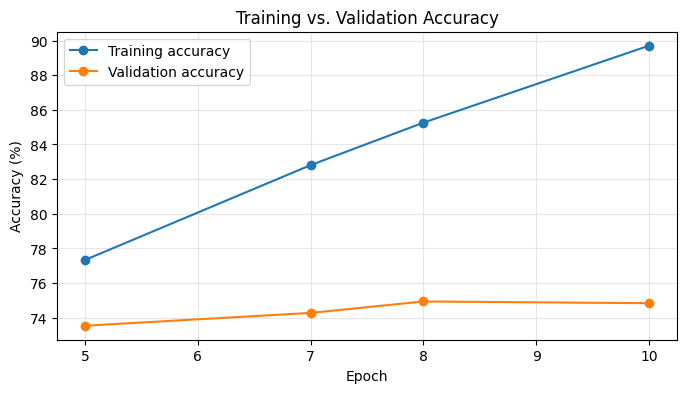

In [2]:
plt.figure(figsize=(8, 4))
plt.plot(df["epoch"], df["train_accuracy"], marker="o", label="Training accuracy")
plt.plot(df["epoch"], df["val_accuracy"], marker="o", label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs. Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Training accuracy tells me how well the model performs on the data it learns from. Validation accuracy checks performance on separate data during training. If training accuracy keeps rising but validation accuracy stops improving, that can be a sign of overfitting.

3. Check validation loss

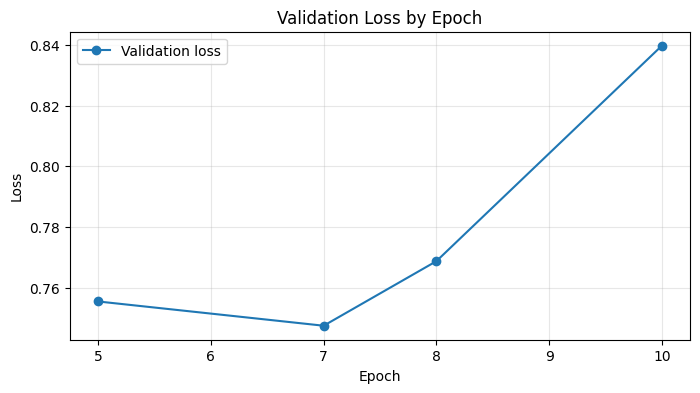

In [3]:
plt.figure(figsize=(8, 4))
plt.plot(df["epoch"], df["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Validation Loss by Epoch")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Validation loss is useful alongside accuracy. In my run, it reached 0.7474 at epoch 7, then rose to 0.8398 by epoch 10 while training accuracy continued to rise. This is another sign that later training was not improving generalization.

4. Calculate the training-validation gap

In [4]:
df["accuracy_gap"] = df["train_accuracy"] - df["val_accuracy"]
df[["epoch", "train_accuracy", "val_accuracy", "accuracy_gap", "val_loss"]]

,epoch,train_accuracy,val_accuracy,accuracy_gap,val_loss
0,5,77.34,73.54,3.80,0.7554
1,7,82.81,74.28,8.53,0.7474
2,8,85.26,74.94,10.32,0.7687
3,10,89.70,74.84,14.86,0.8398


A larger training-validation gap can suggest overfitting, but it does not prove it by itself. I should look at the trend over several epochs and use validation loss as well as accuracy.

5. Training, validation, and test sets

- **Training set:** used to calculate gradients and update the model weights.
- **Validation set:** used during development to compare settings and decide when to stop.
- **Test set:** held back for a final evaluation after model choices are made.

I should not use test results to repeatedly tune the model, because then the test set is no longer a fair final check.

6. Accuracy and loss are different

Accuracy measures the fraction of predictions that are correct. Loss measures how wrong the model's predictions are according to the chosen loss function. A model can have similar accuracy but a higher loss if it becomes more confident in incorrect predictions.

7. My conclusion

From my Module 1 run, training accuracy reached 89.70%, but validation accuracy stayed around 75%. Validation loss also rose after epoch 7. This suggests overfitting in the later epochs. The test accuracy was 74.39%, so the model still met the Module 1 target, but I have a reason to try techniques that improve generalization in the next lessons.